In [14]:
import numpy as np
from sklearn.model_selection import KFold, TimeSeriesSplit

# Simulasi 10 titik waktu berurutan
X_dummy = np.array([[i] for i in range(10)])

# [SALAH] K-Fold Tradisional (Mengacak urutan / memutus kronologi)
kf = KFold(n_splits=3, shuffle=True, random_state=42)
print("Standard K-Fold (Contoh Kebocoran Data):")
for train_index, test_index in kf.split(X_dummy):
    print(f"Train: {train_index} | Test: {test_index}")

print("-" * 50)

# [BENAR] Time Series Split (Menjaga kronologi)
tscv = TimeSeriesSplit(n_splits=3)
print("Time Series Split (Aman dari Kebocoran):")
for train_index, test_index in tscv.split(X_dummy):
    print(f"Train: {train_index} | Test: {test_index}")

Standard K-Fold (Contoh Kebocoran Data):
Train: [2 3 4 6 7 9] | Test: [0 1 5 8]
Train: [0 1 3 4 5 6 8] | Test: [2 7 9]
Train: [0 1 2 5 7 8 9] | Test: [3 4 6]
--------------------------------------------------
Time Series Split (Aman dari Kebocoran):
Train: [0 1 2 3] | Test: [4 5]
Train: [0 1 2 3 4 5] | Test: [6 7]
Train: [0 1 2 3 4 5 6 7] | Test: [8 9]


In [15]:
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit

# Simulasi data harian selama 20 hari
dates = pd.date_range("2026-01-01", periods=20)
df_cv = pd.DataFrame({'Value': range(20)}, index=dates)

# Mengatur TimeSeriesSplit dengan 4 iterasi pengujian
tscv = TimeSeriesSplit(n_splits=4)

iterasi = 1
for train_index, test_index in tscv.split(df_cv):
    train_dates = df_cv.index[train_index]
    test_dates = df_cv.index[test_index]
    
    print(f"Iterasi {iterasi}:")
    print(f"  Periode Train: {train_dates.min().date()} hingga {train_dates.max().date()}")
    print(f"  Periode Test : {test_dates.min().date()} hingga {test_dates.max().date()}\n")
    iterasi += 1

Iterasi 1:
  Periode Train: 2026-01-01 hingga 2026-01-04
  Periode Test : 2026-01-05 hingga 2026-01-08

Iterasi 2:
  Periode Train: 2026-01-01 hingga 2026-01-08
  Periode Test : 2026-01-09 hingga 2026-01-12

Iterasi 3:
  Periode Train: 2026-01-01 hingga 2026-01-12
  Periode Test : 2026-01-13 hingga 2026-01-16

Iterasi 4:
  Periode Train: 2026-01-01 hingga 2026-01-16
  Periode Test : 2026-01-17 hingga 2026-01-20



In [16]:
from xgboost import XGBRegressor

# Mendefinisikan model dengan parameter yang dirancang untuk mencegah overfitting
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=4,         # Dibatasi agar tidak terlalu dalam
    subsample=0.8,       # Hanya menggunakan 80% data pada tiap pohon
    random_state=42
)

In [17]:
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error

np.random.seed(42)
n_samples = 200

X = np.arange(n_samples).reshape(-1, 1) 
y = 0.5 * X.flatten() + 10 * np.sin(X.flatten() / 5) + np.random.normal(0, 2, n_samples)
split_point = int(n_samples * 0.8)
X_train_full, X_test = X[:split_point], X[split_point:]
y_train_full, y_test = y[:split_point], y[split_point:]

param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}

base_model = XGBRegressor(
    subsample=0.8,      
    random_state=42
)
tscv_tuning = TimeSeriesSplit(n_splits=3)

grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    cv=tscv_tuning,      
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
)

grid_search.fit(X_train_full, y_train_full)

print("\n=== HASIL TUNING ===")
print("Parameter Terbaik:", grid_search.best_params_)
# Nilai dikalikan -1 karena scoring menggunakan 'neg_mean_absolute_error'
print(f"MAE Validasi Terbaik: {-grid_search.best_score_:.2f}")


=== HASIL TUNING ===
Parameter Terbaik: {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 100}
MAE Validasi Terbaik: 13.51


Studi Kasus

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.deterministic import DeterministicProcess

np.random.seed(42)
waktu = pd.date_range("2020-01-01", periods=500, freq="D")
tren = np.linspace(10, 100, 500)
musiman = np.sin(np.arange(500) * (2 * np.pi / 30)) * 20 # Siklus 30 harian
penjualan = tren + musiman + np.random.normal(0, 5, 500)

df = pd.DataFrame({'Sales': penjualan}, index=waktu)

test_size = 60
df_train = df.iloc[:-test_size].copy()
df_test = df.iloc[-test_size:].copy()

In [19]:
# Pembuatan Fitur Waktu (Tren)
dp = DeterministicProcess(index=df.index, order=1, constant=True)
X_trend_full = dp.in_sample()

X_trend_train = X_trend_full.iloc[:-test_size]
X_trend_test = X_trend_full.iloc[-test_size:]

# Pelatihan Model Tren (Regresi Linear)
model_trend = LinearRegression()
model_trend.fit(X_trend_train, df_train['Sales'])

# Menyimpan prediksi tren
pred_trend_train = pd.Series(model_trend.predict(X_trend_train), index=df_train.index)
pred_trend_test = pd.Series(model_trend.predict(X_trend_test), index=df_test.index)

# Ekstraksi Residual pada data pelatihan
residual_train = df_train['Sales'] - pred_trend_train

X_season_full = pd.DataFrame({'Cycle_30': np.arange(len(df)) % 30}, index=df.index)

X_season_train = X_season_full.iloc[:-test_size]
X_season_test = X_season_full.iloc[-test_size:]

In [20]:
# Pengaturan Grid Parameter
param_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5],
    'subsample': [0.8, 1.0]
}

# Pengaturan Time Series Split (5 Lipatan pada sisa data latih)
tscv = TimeSeriesSplit(n_splits=5)

# Eksekusi Grid Search
grid_search = GridSearchCV(
    estimator=XGBRegressor(random_state=42),
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid_search.fit(X_season_train, residual_train)

# Ekstraksi model XGBoost terbaik
best_xgb_model = grid_search.best_estimator_

print("Parameter XGBoost Terbaik:", grid_search.best_params_)

Parameter XGBoost Terbaik: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50, 'subsample': 0.8}


Mean Absolute Error (Test Set): 4.25


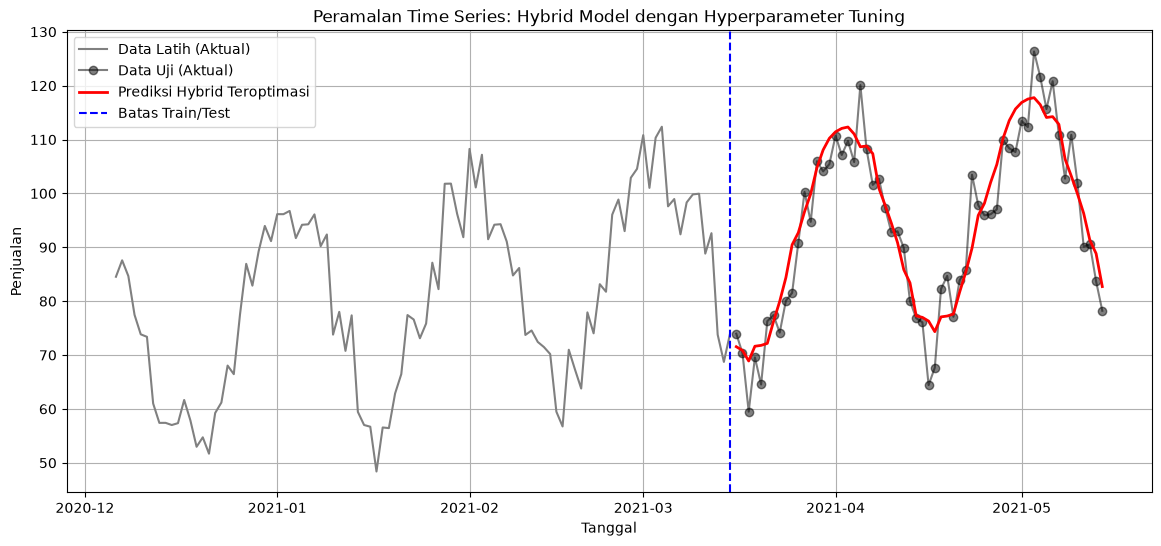

In [21]:
# Prediksi residual pada set pengujian menggunakan model XGBoost terbaik
pred_residual_test = pd.Series(best_xgb_model.predict(X_season_test), index=df_test.index)

# REKONSTRUKSI: Final Prediksi = Prediksi Tren + Prediksi Residual
pred_final_test = pred_trend_test + pred_residual_test

# Evaluasi Akhir
mae = mean_absolute_error(df_test['Sales'], pred_final_test)
print(f"Mean Absolute Error (Test Set): {mae:.2f}")

# Visualisasi
plt.figure(figsize=(14, 6))

# Plot Data Historis (Sebagian agar lebih jelas)
plt.plot(df_train.index[-100:], df_train['Sales'].iloc[-100:], label='Data Latih (Aktual)', color='gray')

# Plot Data Aktual Test Set
plt.plot(df_test.index, df_test['Sales'], label='Data Uji (Aktual)', marker='o', color='black', alpha=0.5)

# Plot Hasil Forecasting Final
plt.plot(df_test.index, pred_final_test, label='Prediksi Hybrid Teroptimasi', color='red', linewidth=2)

plt.title("Peramalan Time Series: Hybrid Model dengan Hyperparameter Tuning")
plt.xlabel("Tanggal")
plt.ylabel("Penjualan")
plt.axvline(x=df_train.index[-1], color='blue', linestyle='--', label='Batas Train/Test')
plt.legend()
plt.grid(True)
plt.show()

ASSIGNMENT

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.deterministic import DeterministicProcess

# ==========================================
# Bagian 1: Pra-pemrosesan Data
# ==========================================
df = pd.read_csv('Microsoft_Stock.csv')
df.head(5)

,Date,Open,High,Low,Close,Volume
0,4/1/2015 16:00:00,40.60,40.76,40.31,40.72,36865322
1,4/2/2015 16:00:00,40.66,40.74,40.12,40.29,37487476
2,4/6/2015 16:00:00,40.34,41.78,40.18,41.55,39223692
3,4/7/2015 16:00:00,41.61,41.91,41.31,41.53,28809375
4,4/8/2015 16:00:00,41.48,41.69,41.04,41.42,24753438


In [23]:
df.tail(5)

,Date,Open,High,Low,Close,Volume
1506,3/25/2021 16:00:00,235.30,236.94,231.57,232.34,34061853
1507,3/26/2021 16:00:00,231.55,236.71,231.55,236.48,25479853
1508,3/29/2021 16:00:00,236.59,236.80,231.88,235.24,25227455
1509,3/30/2021 16:00:00,233.53,233.85,231.10,231.85,24792012
1510,3/31/2021 16:00:00,232.91,239.10,232.39,235.77,43623471


Parameter XGBoost Terbaik: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Mean Absolute Error (Hold-out Test) TERBARU: 4.13


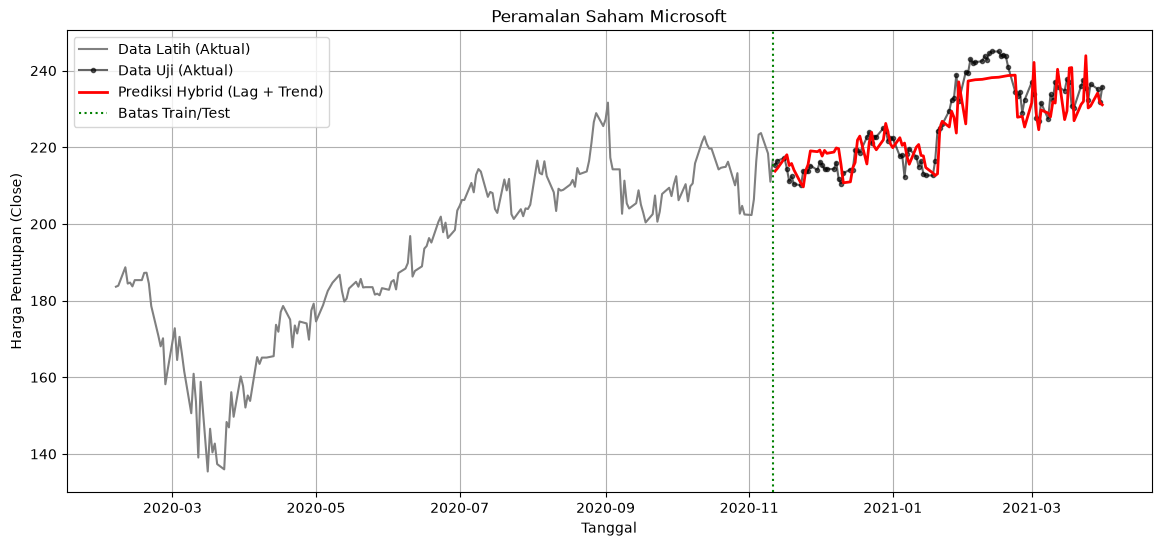

In [24]:
df['Date'] = pd.to_datetime(df['Date']).dt.normalize()
df = df.set_index('Date').sort_index()
df = df.resample('B').ffill()

y = df['Close']
test_size = 100 

# ==========================================
# Bagian 2: Model 1 - Regresi Linier (Tren)
# ==========================================
# 1. Fitur Tren
dp = DeterministicProcess(index=y.index, order=1, constant=True)
X_trend = dp.in_sample()

# Split Data untuk Tren
y_train_full = y.iloc[:-test_size]
y_test = y.iloc[-test_size:]
X_trend_train = X_trend.iloc[:-test_size]
X_trend_test = X_trend.iloc[-test_size:]

# 2. Pelatihan Model Tren
model_trend = LinearRegression()
model_trend.fit(X_trend_train, y_train_full)

# 3. Prediksi Tren & Hitung Kesalahan (Residual)
pred_trend_train = pd.Series(model_trend.predict(X_trend_train), index=y_train_full.index)
pred_trend_test = pd.Series(model_trend.predict(X_trend_test), index=y_test.index)

# Menyatukan kembali target untuk keperluan pembuatan Lag (Shift)
residual_full = y - pd.concat([pred_trend_train, pred_trend_test])

# ==========================================
# Bagian 3: PERBAIKAN - Ekstraksi Fitur Lag
# ==========================================
# Mengganti fitur "Bulan/Kuartal" dengan Harga Masa Lalu (Lag 1, 2, 3)
X_lag = pd.DataFrame({
    'Lag_1': residual_full.shift(1),
    'Lag_2': residual_full.shift(2),
    'Lag_3': residual_full.shift(3)
})

# PENTING: Pergeseran (Shift) menghasilkan nilai kosong (NaN) di 3 baris pertama.
# Baris ini harus dibuang agar algoritma tidak error.
valid_idx = X_lag.dropna().index
X_lag = X_lag.loc[valid_idx]
residual_full = residual_full.loc[valid_idx]

# Menyelaraskan ulang indeks Train dan Test agar bebas dari NaN
train_idx = y_train_full.index.intersection(valid_idx)
test_idx = y_test.index

X_lag_train = X_lag.loc[train_idx]
X_lag_test = X_lag.loc[test_idx]
resid_train = residual_full.loc[train_idx]

# ==========================================
# Bagian 4: Model 2 - XGBoost (Tuning)
# ==========================================
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5]
}

tscv = TimeSeriesSplit(n_splits=4)
grid_search = GridSearchCV(
    estimator=XGBRegressor(random_state=42),
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

# XGBoost kini belajar dari relasi harga hari ini dengan hari sebelumnya
grid_search.fit(X_lag_train, resid_train)
best_xgb = grid_search.best_estimator_

print("Parameter XGBoost Terbaik:", grid_search.best_params_)

# ==========================================
# Bagian 5: Prediksi Final & Evaluasi
# ==========================================
pred_resid_test = pd.Series(best_xgb.predict(X_lag_test), index=X_lag_test.index)

# Rekonstruksi: Tren + Siklus/Lag
final_predictions = pred_trend_test + pred_resid_test

# Evaluasi
mae = mean_absolute_error(y_test, final_predictions)
print(f"Mean Absolute Error (Hold-out Test) TERBARU: {mae:.2f}")

# Visualisasi
plt.figure(figsize=(14, 6))

plt.plot(y_train_full.index[-200:], y_train_full.iloc[-200:], label='Data Latih (Aktual)', color='gray')
plt.plot(y_test.index, y_test, label='Data Uji (Aktual)', color='black', marker='.', alpha=0.6)
plt.plot(final_predictions.index, final_predictions, label='Prediksi Hybrid (Lag + Trend)', color='red', linewidth=2)

plt.title("Peramalan Saham Microsoft")
plt.xlabel("Tanggal")
plt.ylabel("Harga Penutupan (Close)")
plt.axvline(x=y_train_full.index[-1], color='green', linestyle=':', label='Batas Train/Test')
plt.legend()
plt.grid(True)
plt.show()

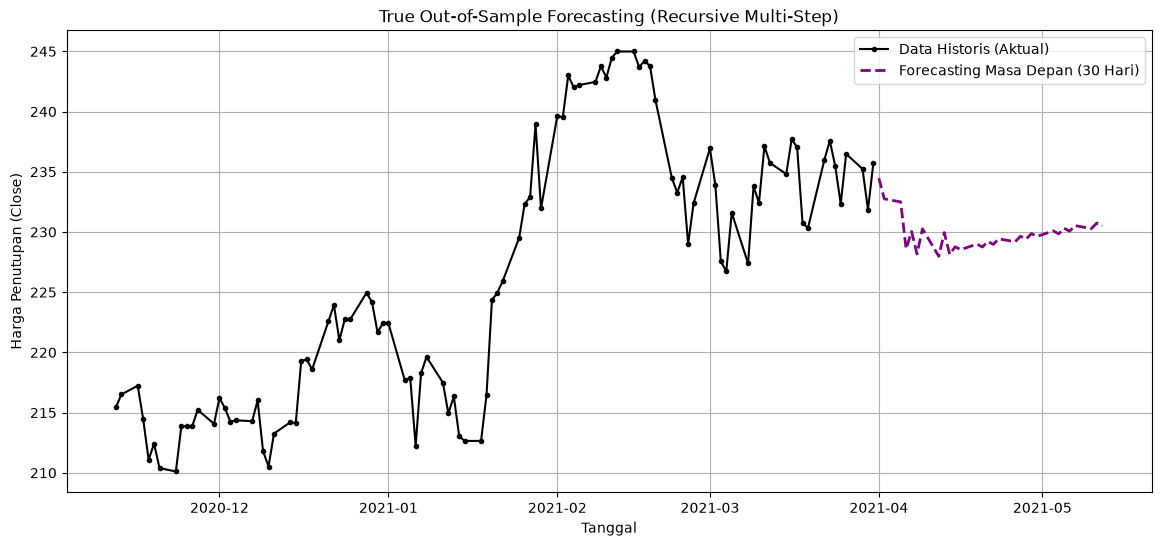

In [25]:
# ==========================================
# Bagian 6: TRUE OUT-OF-SAMPLE FORECASTING (RECURSIVE)
# Memprediksi 30 Hari Kerja ke depan (Masa Depan Murni)
# ==========================================
future_steps = 30

# 1. Buat Indeks Waktu Masa Depan (30 Hari Kerja ke depan)
last_date = y.index[-1]
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=future_steps, freq='B')

# 2. Ekstrapolasi Tren untuk 30 Hari Kedepan menggunakan Regresi Linier
# DeterministicProcess secara otomatis dapat menghasilkan fitur waktu ke masa depan
X_trend_future = dp.out_of_sample(steps=future_steps)
pred_trend_future = pd.Series(model_trend.predict(X_trend_future), index=future_dates)

# 3. Siapkan Array untuk menyimpan prediksi residual
# Ambil 3 nilai residual TERAKHIR dari data historis sebagai titik awal (Lag 3, Lag 2, Lag 1)
# Urutan: [Lag_3, Lag_2, Lag_1]
last_known_residuals = residual_full.iloc[-3:].tolist()
future_residuals = []

# 4. Looping Rekursif (Memasukkan prediksi hari ini sebagai Lag untuk besok)
for i in range(future_steps):
    # Siapkan DataFrame 1 baris yang berisi Lag saat ini
    current_lags = pd.DataFrame({
        'Lag_1': [last_known_residuals[-1]],
        'Lag_2': [last_known_residuals[-2]],
        'Lag_3': [last_known_residuals[-3]]
    })
    
    # Prediksi residual untuk hari ini menggunakan XGBoost
    pred_res = best_xgb.predict(current_lags)[0]
    future_residuals.append(pred_res)
    
    # UPDATE LAGS: Masukkan prediksi terbaru ke akhir list, buang yang paling lama
    # Sehingga array bergeser maju 1 hari
    last_known_residuals.append(pred_res)
    last_known_residuals.pop(0)

# Konversi list residual masa depan menjadi Pandas Series
pred_residual_future = pd.Series(future_residuals, index=future_dates)

# 5. Rekonstruksi Prediksi Masa Depan = Tren Masa Depan + Residual Masa Depan
true_out_of_sample_forecast = pred_trend_future + pred_residual_future

# ==========================================
# Visualisasi Forecasting Masa Depan
# ==========================================
plt.figure(figsize=(14, 6))

# Plot 100 hari terakhir dari data aktual sebagai konteks
plt.plot(y.index[-100:], y.iloc[-100:], label='Data Historis (Aktual)', color='black', marker='.')

# Plot hasil forecasting murni ke masa depan
plt.plot(true_out_of_sample_forecast.index, true_out_of_sample_forecast, 
         label='Forecasting Masa Depan (30 Hari)', color='purple', linestyle='--', linewidth=2)

plt.title("True Out-of-Sample Forecasting (Recursive Multi-Step)")
plt.xlabel("Tanggal")
plt.ylabel("Harga Penutupan (Close)")
plt.legend()
plt.grid(True)
plt.show()